# DVL Modelling Variations: Simulation Study (Options A–D)
**Tejas Jadhav** · B.Tech Mechatronics Engineering, Symbiosis Skills and Professional University · 30 October 2026

This notebook follows the faculty plan: four variations on the paper's DVL model, each compared with the paper's baseline
in **three scenarios** using **200 Monte Carlo runs**, scored on the same parameter list.

| Option | Variation | Baseline it is compared with |
|---|---|---|
| **A** | Hydrodynamic model-aided EKF (vehicle drag + thrust model, 3 model-error states) | Kinematic 9-state EKF (paper) and INS only |
| **B** | Beam geometry: Janus 20°/25°/35°, 5-beam (4 + vertical), non-orthogonal azimuths | 4-beam Janus at 30° (paper) |
| **C** | Adaptive measurement noise R: from slant range + seabed slope, or from innovations | Fixed σ_r (paper) |
| **D** | Recovering a lost/quarantined beam: geometric reconstruction or ML (ridge regression) | Discard the beam (paper) |

**Scenarios:** S1 nominal · S2 beam fault 0.1 m/s at t = 30 s (step, and a 10 s ramp) · S3 full DVL outage t = 20–35 s.

**Parameters:** position RMSE, velocity RMSE, false-alarm rate P_FA, fault isolation rate, detection latency, outage drift rate,
filter consistency (NEES; ideal = 6), execution time per update.

**Ground truth.** No recorded dataset is used. The simulator generates the true trajectory (and, for B/C, the true seabed),
so every error is *estimate − known truth*. This is the standard simulation-based benchmarking method; it verifies the
method under the stated assumptions, not the hardware.

**Run time:** about 15–25 minutes on Colab for everything (`N_MC = 200`). Set `N_MC = 50` for a quick pass.

## 0. Core library (baseline filter + the four variation hooks)

In [1]:
"""Shared core for the DVL variation study (Options A-D).

Baseline = the 9-state INS/DVL EKF with beam-level fault detection from the
project notebook (AUV_DVL_Navigation_Study.ipynb). Every option switches on
one change; everything else stays identical, so differences come only from
that change.

Ground truth: the simulator generates the true trajectory (and, for C, the
true seabed), so every error is estimate minus a known truth.
"""
import time
import numpy as np
from dataclasses import dataclass

# ----------------------------------------------------------------------------
# Configuration (same defaults as the paper / notebook)
# ----------------------------------------------------------------------------
@dataclass(frozen=True)
class Cfg:
    f0: float = 1.0e6          # carrier [Hz]
    c: float = 1500.0          # sound speed [m/s]
    imu_rate: float = 100.0    # [Hz]
    dvl_rate: float = 5.0      # [Hz]
    T: float = 60.0            # mission length [s]
    sigma_acc: float = 0.02    # accelerometer white noise per sample [m/s^2]
    sigma_bias: float = 0.005  # accelerometer bias 1-sigma per axis [m/s^2]
    q_bias: float = 1e-8       # bias random-walk PSD in the filter
    noise_hz: float = 10.0     # per-beam Doppler noise [Hz]
    k_sigma: float = 4.0       # fault threshold
    hold_s: float = 2.0        # quarantine hold time [s]

CFG = Cfg()
hz2mps = lambda hz, cfg=CFG: cfg.c * hz / (2 * cfg.f0)


# ----------------------------------------------------------------------------
# Beam geometries (rows = unit beam vectors, z down)
# ----------------------------------------------------------------------------
def janus(theta_deg=30.0, az_deg=(0, 180, 90, 270)):
    s, c = np.sin(np.radians(theta_deg)), np.cos(np.radians(theta_deg))
    return np.array([[s * np.cos(np.radians(a)), s * np.sin(np.radians(a)), c] for a in az_deg])

def five_beam(theta_deg=30.0):
    return np.vstack([janus(theta_deg), [0.0, 0.0, 1.0]])

B_BASE = janus(30.0)


# ----------------------------------------------------------------------------
# Ground truth trajectory (identical to the paper's 60 s manoeuvre)
# ----------------------------------------------------------------------------
def truth_trajectory(T=CFG.T, dt=1 / CFG.imu_rate):
    t = np.arange(0, T + 1e-9, dt)
    a = np.stack([0.20 * np.sin(2 * np.pi * t / 20), 0.10 * np.cos(2 * np.pi * t / 15),
                  0.05 * np.sin(2 * np.pi * t / 30)], 1)
    v = np.zeros_like(a); p = np.zeros_like(a); v[0] = [1.0, 0.4, 0.2]
    for k in range(len(t) - 1):
        p[k + 1] = p[k] + v[k] * dt + 0.5 * a[k] * dt ** 2
        v[k + 1] = v[k] + a[k] * dt
    return t, a, v, p


# ----------------------------------------------------------------------------
# Option A: simple hydrodynamic model (surge/sway/heave, body = nav frame)
# Representative small-AUV parameters (assumed, ~30 kg vehicle)
# ----------------------------------------------------------------------------
HYDRO = dict(M=np.array([33.0, 55.0, 55.0]),       # mass + added mass [kg]
             Dl=np.array([4.0, 20.0, 20.0]),       # linear drag [N s/m]
             Dq=np.array([12.0, 60.0, 60.0]))      # quadratic drag [N s^2/m^2]

def hydro_force(v_rel, M, Dl, Dq):
    return -(Dl * v_rel + Dq * np.abs(v_rel) * v_rel)

def thrust_profile(a, v, current, P=HYDRO):
    """Thrust that makes the TRUE vehicle (with current) follow the truth trajectory."""
    v_rel = v[None] - current[:, None, :]                      # (N, K, 3)
    return P["M"] * a[None] - hydro_force(v_rel, P["M"], P["Dl"], P["Dq"])


# ----------------------------------------------------------------------------
# Option C: seabed + altitude/slope-dependent beam noise
# ----------------------------------------------------------------------------
def seabed_depth(x, y):
    """True seabed depth [m, positive down] under the 60 s path: slope + ridges."""
    return 30.0 + 0.12 * x + 5.0 * np.sin(x / 9.0) + 3.0 * np.cos(y / 6.0)

def seabed_grad(x, y):
    return 0.12 + (5.0 / 9.0) * np.cos(x / 9.0), -(3.0 / 6.0) * np.sin(y / 6.0)

VEH_DEPTH0 = 6.0      # vehicle starts 6 m below the surface

def beam_geometry_truth(p_k, Bm):
    """Slant range and incidence angle of each beam on the true seabed (local plane)."""
    x, y, z = p_k[0], p_k[1], VEH_DEPTH0 + p_k[2]
    gx, gy = seabed_grad(x, y)
    n = np.array([-gx, -gy, 1.0]); n /= np.linalg.norm(n)        # seabed normal (z down)
    h = seabed_depth(x, y) - z
    # ray-plane intersection: z + R bz = depth(x + R bx, y + R by) ~ h + gx R bx + gy R by
    denom = Bm[:, 2] - gx * Bm[:, 0] - gy * Bm[:, 1]
    R = h / np.maximum(denom, 0.05)
    cos_inc = np.clip(np.abs(Bm @ n), 0.2, 1.0)
    return R, cos_inc, h

def alpha_db_per_m(f_khz=1000.0, T=15.0, S=35.0, D=10.0, pH=8.0):
    """Francois-Garrison absorption [dB/m] (same formula as the notebook)."""
    c = 1412 + 3.21 * T + 1.19 * S + 0.0167 * D; f = f_khz
    A1 = 8.86 / c * 10 ** (0.78 * pH - 5); f1 = 2.8 * np.sqrt(S / 35) * 10 ** (4 - 1245 / (T + 273))
    A2 = 21.44 * S / c * (1 + 0.025 * T); P2 = 1 - 1.37e-4 * D + 6.2e-9 * D ** 2
    f2 = 8.17 * 10 ** (8 - 1990 / (T + 273)) / (1 + 0.0018 * (S - 35))
    P3 = 1 - 3.83e-5 * D + 4.9e-10 * D ** 2
    A3 = 4.937e-4 - 2.59e-5 * T + 9.11e-7 * T ** 2 - 1.5e-8 * T ** 3
    return (A1 * f1 * f ** 2 / (f1 ** 2 + f ** 2) + A2 * P2 * f2 * f ** 2 / (f2 ** 2 + f ** 2) + A3 * P3 * f ** 2) / 1000

ALPHA = alpha_db_per_m()
LOCK_SNR_DB = 6.0     # below this the beam loses bottom lock
NOISE_C = dict(snr0_db=42.0, r0=10.0, floor_hz=7.0, snr_hz=45.0)

def beam_noise_hz(R, cos_inc, prm=NOISE_C):
    """Per-beam Doppler noise: speckle floor broadened by incidence + SNR term from the sonar equation."""
    snr_db = prm["snr0_db"] - 40 * np.log10(np.maximum(R, 1) / prm["r0"]) - 2 * ALPHA * R
    snr = 10 ** (snr_db / 10)
    return np.sqrt((prm["floor_hz"] / cos_inc) ** 2 + prm["snr_hz"] ** 2 / snr), snr_db


# ----------------------------------------------------------------------------
# The filter: baseline EKF + optional variations, vectorised over N runs
# ----------------------------------------------------------------------------
def run(N=200, seed=0, cfg=CFG, Bm=B_BASE, dvl=True, outage=None, fault=None,
        failed_beams=(), t_fail=10.0, fdi=True,
        hydro=False, hydro_sigma=0.01, hydro_param_err=0.15, current_sigma=0.05, hydro_q=4e-5, hydro_e0=0.15,
        noise="fixed", adapt="none", recover="discard", log_every=10, bias_rw=0.0, sigma_acc=None, noise_scale=1.0, ml_lambda=1e-6, ml_inflate=1.0):
    """
    noise : 'fixed'  -> every beam has cfg.noise_hz (paper baseline)
            'terrain'-> Option C truth: noise from slant range + incidence
    adapt : 'none'   -> filter uses fixed sigma_r = cfg.noise_hz (baseline)
            'model'  -> Option C: sigma_r from measured range + fitted slope
            'innov'  -> Option C2: innovation-based (sliding window) estimate
    recover: 'discard' (baseline) | 'geometric' | 'ml'   (Option D)
    fault : dict(beams=(N,) or (N,2) int array, mag, t_start, kind='step'|'ramp', ramp_s)
    """
    rng = np.random.default_rng(seed)
    dt = 1 / cfg.imu_rate
    s_acc = cfg.sigma_acc if sigma_acc is None else sigma_acc
    q_b = max(cfg.q_bias, bias_rw ** 2)
    t, a, v, p = truth_trajectory(cfg.T, dt); K = len(t)
    n = Bm.shape[0]; n_dvl = int(round(cfg.imu_rate / cfg.dvl_rate))
    sig_fixed = hz2mps(cfg.noise_hz * noise_scale, cfg)

    b_true = rng.normal(0, cfg.sigma_bias, (N, 3))
    I3 = np.eye(3); ns = 12 if hydro else 9          # Option A adds 3 model-error states
    F = np.eye(ns); F[0:3, 3:6] = I3 * dt; F[0:3, 6:9] = -0.5 * I3 * dt ** 2; F[3:6, 6:9] = -I3 * dt
    G = np.zeros((ns, 3)); G[0:3] = 0.5 * I3 * dt ** 2; G[3:6] = I3 * dt
    Q = G @ G.T * s_acc ** 2; Q[6:9, 6:9] = I3 * q_b * dt
    if hydro: Q[9:12, 9:12] = I3 * hydro_q * dt
    x = np.zeros((N, ns))
    x[:, 0:3] = p[0] + rng.normal(0, 0.01, (N, 3)); x[:, 3:6] = v[0] + rng.normal(0, 0.05, (N, 3))
    P = np.tile(np.diag([1e-4] * 3 + [0.05 ** 2] * 3 + [cfg.sigma_bias ** 2] * 3 + ([hydro_e0 ** 2] * 3 if hydro else [])), (N, 1, 1))
    H = np.zeros((n, ns)); H[:, 3:6] = Bm

    # --- Option A set-up: true thrust, filter's (wrong) parameters, unknown current
    if hydro:
        current = rng.normal(0, current_sigma, (N, 3)); current[:, 2] = 0.0
        tau_true = thrust_profile(a, v, current)                                  # (N, K, 3)
        tau_meas = tau_true * (1 + rng.normal(0, 0.03, (N, 1, 3)))               # thrust known to ~3 %
        Mf = HYDRO["M"] * (1 + rng.normal(0, hydro_param_err, (N, 3)))
        Dlf = HYDRO["Dl"] * (1 + rng.normal(0, hydro_param_err, (N, 3)))
        Dqf = HYDRO["Dq"] * (1 + rng.normal(0, hydro_param_err, (N, 3)))
        n_h = 10; acc_buf = np.zeros((N, 3)); R_h = hydro_sigma ** 2 + cfg.sigma_acc ** 2 / n_h

    # --- Option C2 innovation-adaptive memory
    if adapt == "innov":
        W = 25; r2_hist = np.full((N, n, W), np.nan); r2_ptr = 0

    # --- Option D: online ridge-regression accumulators (target beam j from other beams + IMU)
    nf = n - 1 + 3 + 1
    if recover == "ml":
        drop = set(failed_beams)
        feat_idx = [[i for i in range(n) if i != j and i not in drop] for j in range(n)]
        XtX = np.zeros((N, n, nf, nf)); Xty = np.zeros((N, n, nf)); yy = np.zeros((N, n)); cnt = np.zeros((N, n))
        acc_epoch = np.zeros((N, 3))

    idx_s = np.arange(0, K, log_every); Ks = len(idx_s)
    pos_err = np.zeros((N, Ks, 3)); vel_err = np.zeros((N, Ks, 3))
    nees = np.zeros((N, Ks))
    ep = dict(t=[], z=[], flag=[], excl=[], avail=[], faulty=[], sig_true=[], sig_used=[], pseudo=[])
    hold = int(round(cfg.hold_s * cfg.dvl_rate)); quar = np.zeros((N, n), int); hist = np.zeros((N, n), int)
    t_dvl = 0.0; n_upd = 0

    for k in range(K):
        if k > 0:
            if bias_rw > 0: b_true = b_true + rng.normal(0, bias_rw * np.sqrt(dt), (N, 3))
            a_m = a[k - 1] + b_true + rng.normal(0, s_acc, (N, 3))
            acc = a_m - x[:, 6:9]
            x[:, 0:3] += x[:, 3:6] * dt + 0.5 * acc * dt ** 2
            x[:, 3:6] += acc * dt
            P = F @ P @ F.T + Q
            if recover == "ml": acc_epoch += a_m / n_dvl
            # ---- Option A: hydrodynamic model pseudo-measurement at 10 Hz
            if hydro:
                acc_buf += a_m / n_h
                if k % n_h == 0:
                    vh = x[:, 3:6]
                    drag = hydro_force(vh, Mf, Dlf, Dqf); tau_k = tau_meas[:, k]
                    f_model = (tau_k + drag) / Mf
                    dfdv = -(Dlf + 2 * Dqf * np.abs(vh)) / Mf
                    # constant errors (current, thrust scale, drag coefficients) live in the
                    # model-error states x[9:12]; only white noise goes in R
                    R_ax = hydro_sigma ** 2 + s_acc ** 2 / n_h
                    for ax_ in range(3):
                        h = np.zeros((N, ns)); h[:, 3 + ax_] = dfdv[:, ax_]; h[:, 6 + ax_] = 1.0; h[:, 9 + ax_] = 1.0
                        Ph = np.einsum("nij,nj->ni", P, h); s_ = np.einsum("ni,ni->n", Ph, h) + R_ax
                        Kg = Ph / s_[:, None]
                        y = acc_buf[:, ax_] - (f_model[:, ax_] + x[:, 6 + ax_] + x[:, 9 + ax_])
                        x += y[:, None] * Kg
                        P -= Kg[:, :, None] * Ph[:, None, :]
                    acc_buf[:] = 0.0

        if dvl and k > 0 and k % n_dvl == 0:
            t0c = time.perf_counter()
            tk = t[k]
            # ---- truth beam noise
            if noise == "terrain":
                R_tr, cinc, _ = beam_geometry_truth(p[k], Bm)
                hz_true, snr_db = beam_noise_hz(R_tr, cinc)
                sig_true = np.tile(hz2mps(hz_true * noise_scale, cfg), (N, 1))
                lock = np.tile(snr_db >= LOCK_SNR_DB, (N, 1))
            else:
                sig_true = np.full((N, n), sig_fixed)
            zr = (Bm @ v[k])[None, :] + rng.normal(0, 1, (N, n)) * sig_true
            avail = np.ones((N, n), bool) if noise != "terrain" else lock.copy()
            if outage and outage[0] <= tk < outage[1]: avail[:] = False
            if len(failed_beams) and tk >= t_fail: avail[:, list(failed_beams)] = False
            faulty = np.zeros((N, n), bool)
            if fault is not None and tk >= fault["t_start"]:
                fb = np.asarray(fault["beams"]).reshape(N, -1)
                mag = fault["mag"]
                if fault.get("kind", "step") == "ramp":
                    mag = mag * min(1.0, (tk - fault["t_start"]) / fault.get("ramp_s", 10.0))
                for col in range(fb.shape[1]):
                    faulty[np.arange(N), fb[:, col]] = True
                    zr[np.arange(N), fb[:, col]] += mag
            # ---- filter's noise assumption
            if adapt == "model":
                R_tr, cinc, _ = beam_geometry_truth(p[k], Bm)
                R_meas = R_tr[None] * (1 + rng.normal(0, 0.02, (N, n)))          # range from echo timing
                # slope from beam ranges: least-squares plane through the 4 footprints
                pts = R_meas[:, :, None] * Bm[None]                               # (N, n, 3)
                A_ = np.concatenate([pts[:, :, :2], np.ones((N, n, 1))], 2)
                coef = np.einsum("nij,nj->ni", np.linalg.pinv(A_), pts[:, :, 2])  # z = gx x + gy y + h
                nrm = np.stack([-coef[:, 0], -coef[:, 1], np.ones(N)], 1)
                nrm /= np.linalg.norm(nrm, axis=1, keepdims=True)
                cinc_e = np.clip(np.abs(nrm @ Bm.T), 0.2, 1.0)
                hz_e, _ = beam_noise_hz(R_meas, cinc_e)
                sig_R = hz2mps(hz_e * noise_scale, cfg)
            elif adapt == "innov":
                var_pred_ = np.einsum("ij,njk,ik->ni", Bm, P[:, 3:6, 3:6], Bm)
                with np.errstate(all='ignore'):
                    import warnings; warnings.simplefilter('ignore', RuntimeWarning)
                    est = np.nanmean(r2_hist, axis=2) - var_pred_
                sig_R = np.sqrt(np.clip(np.where(np.isnan(est), sig_fixed ** 2, est), (0.5 * sig_fixed) ** 2, None))
            else:
                sig_R = np.full((N, n), sig_fixed)

            r = zr - x[:, 3:6] @ Bm.T
            var_pred = np.einsum("ij,njk,ik->ni", Bm, P[:, 3:6, 3:6], Bm)
            S = var_pred + sig_R ** 2
            z = r / np.sqrt(S)
            flag = avail & (np.abs(z) > cfg.k_sigma) if fdi else np.zeros((N, n), bool)
            excl = flag | (avail & (quar > 0))
            hist = ((hist << 1) | flag) & 0b111
            persistent = (hist & 1).astype(bool) & ((hist & 1) + ((hist >> 1) & 1) + ((hist >> 2) & 1) >= 2)
            quar = np.where(persistent, hold, np.where(flag, quar, np.maximum(quar - 1, 0)))
            use = avail & ~excl
            if adapt == "innov":
                r2_hist[:, :, r2_ptr % W] = np.where(use, r ** 2, np.nan); r2_ptr += 1

            # ---- Option D: learn from healthy epochs
            if recover == "ml":
                allok = use.all(1) if not len(failed_beams) else use[:, [i for i in range(n) if i not in failed_beams]].all(1)
                for j in range(n):
                    fi = feat_idx[j]
                    X = np.concatenate([zr[:, fi], acc_epoch, np.ones((N, 1))], 1)
                    X = np.pad(X, ((0, 0), (0, nf - X.shape[1])))
                    m = allok & use[:, j]
                    XtX[:, j] += m[:, None, None] * X[:, :, None] * X[:, None, :]
                    Xty[:, j] += m[:, None] * X * zr[:, j:j + 1]
                    yy[:, j] += m * zr[:, j] ** 2; cnt[:, j] += m

            for i in range(n):
                h = H[i]; m = use[:, i]
                if not m.any(): continue
                Ph = P @ h; s_i = Ph @ h + sig_R[:, i] ** 2; Kg = Ph / s_i[:, None]
                y = zr[:, i] - x @ h
                x += (m * y)[:, None] * Kg
                P -= m[:, None, None] * Kg[:, :, None] * Ph[:, None, :]

            # ---- Option D: pseudo-measurement for missing / quarantined beams
            pseudo = np.zeros((N, n), bool)
            if recover in ("geometric", "ml"):
                in_out = outage is not None and outage[0] <= tk < outage[1]
                missing = ~use & (not in_out)
                for i in range(n):
                    rows = np.where(missing[:, i] & (use.sum(1) >= (3 if recover == "geometric" else 1)))[0]
                    for r_ in rows:
                        if recover == "geometric":
                            ub = np.where(use[r_])[0]
                            vls = np.linalg.lstsq(Bm[ub], zr[r_, ub], rcond=None)[0]
                            zhat = Bm[i] @ vls
                            var = sig_R[r_, i] ** 2 * float(Bm[i] @ np.linalg.inv(Bm[ub].T @ Bm[ub]) @ Bm[i])
                        else:
                            if cnt[r_, i] < 20: continue
                            fi = feat_idx[i]
                            if not use[r_, fi].all(): continue
                            X = np.concatenate([zr[r_, fi], acc_epoch[r_], [1.0]]); X = np.pad(X, (0, nf - X.size))
                            A_ = XtX[r_, i] + ml_lambda * np.eye(nf)
                            wgt = np.linalg.solve(A_, Xty[r_, i])
                            zhat = X @ wgt
                            res = (yy[r_, i] - 2 * wgt @ Xty[r_, i] + wgt @ XtX[r_, i] @ wgt) / max(cnt[r_, i] - nf, 1)
                            var = ml_inflate * max(res, 1e-8)
                        h = H[i]; Ph = P[r_] @ h; s_ = Ph @ h + var; Kg = Ph / s_
                        x[r_] += Kg * (zhat - x[r_] @ h); P[r_] -= np.outer(Kg, Ph)
                        pseudo[r_, i] = True
            if recover == "ml": acc_epoch[:] = 0.0
            P = 0.5 * (P + P.transpose(0, 2, 1))
            t_dvl += time.perf_counter() - t0c; n_upd += 1
            for key, val in zip(["t", "z", "flag", "excl", "avail", "faulty", "sig_true", "sig_used", "pseudo"],
                                [tk, z, flag, excl, avail, faulty, sig_true, sig_R, pseudo]):
                ep[key].append(val)
        if k % log_every == 0:
            j_ = k // log_every
            e = x[:, 0:6] - np.concatenate([p[k], v[k]])
            pos_err[:, j_] = e[:, 0:3]; vel_err[:, j_] = e[:, 3:6]
            Pi = np.linalg.inv(P[:, 0:6, 0:6] + 1e-12 * np.eye(6))
            nees[:, j_] = np.einsum("ni,nij,nj->n", e, Pi, e)
    out = dict(t=t[idx_s], p=p[idx_s], v=v[idx_s], pos_err=pos_err, vel_err=vel_err, nees=nees,
               t_per_update_ms=1e3 * t_dvl / max(n_upd, 1) / N, N=N, n_beams=n)
    if ep["t"]:
        out["ep_t"] = np.array(ep["t"])
        for key in ["z", "flag", "excl", "avail", "faulty", "sig_true", "sig_used", "pseudo"]:
            out[key] = np.stack(ep[key], 1)
    return out


# ----------------------------------------------------------------------------
# Metrics (the faculty's parameter list)
# ----------------------------------------------------------------------------
def rms_t(e):
    """RMS over runs of the error norm, as a function of time."""
    return np.sqrt(np.mean(np.sum(e ** 2, -1), 0))

def rms_h(e):
    return np.sqrt(np.mean(np.sum(e[..., :2] ** 2, -1), 0))

def metrics(o, t_skip=1.0, fault_t0=None, outage=None):
    t = o["t"]; m = {}
    keep = t >= t_skip
    m["pos_rmse_m"] = float(np.sqrt(np.mean(np.sum(o["pos_err"][:, keep] ** 2, -1))))
    m["pos_final_m"] = float(rms_t(o["pos_err"])[-1])
    fe = np.linalg.norm(o["pos_err"][:, -1], axis=1)
    m["pos_final_median_m"] = float(np.median(fe)); m["pos_final_p95_m"] = float(np.percentile(fe, 95))
    m["vel_rmse_mps"] = float(np.sqrt(np.mean(np.sum(o["vel_err"][:, keep] ** 2, -1))))
    m["horiz_rmse_m"] = float(np.sqrt(np.mean(np.sum(o["pos_err"][:, keep, :2] ** 2, -1))))
    m["vert_rmse_m"] = float(np.sqrt(np.mean(o["pos_err"][:, keep, 2] ** 2)))
    m["nees_mean"] = float(np.mean(o["nees"][:, keep]))          # ideal = 6 (6 states)
    if "z" in o:
        et = o["ep_t"]; ok = et >= t_skip
        healthy = o["avail"][:, ok] & ~o["faulty"][:, ok]
        m["P_FA"] = float(o["flag"][:, ok][healthy].mean()) if healthy.any() else np.nan
        zh = o["z"][:, ok][healthy]
        m["z_std"] = float(np.std(zh)) if zh.size else np.nan
        if fault_t0 is not None:
            on = et >= fault_t0
            av = o["avail"][:, on]
            fy, ex = o["faulty"][:, on] & av, o["excl"][:, on] & av      # only beams that have bottom lock
            m["fault_detect"] = float(ex[fy].mean()) if fy.any() else np.nan
            m["fault_isolation"] = float(np.mean(np.all(ex == fy, -1)[fy.any(-1)])) if fy.any() else np.nan
            # latency: first flag of a faulty beam after onset, per run
            lat = []
            for r in range(o["N"]):
                hit = np.where((o["flag"][r, on] & fy[r]).any(-1))[0]
                lat.append(et[on][hit[0]] - fault_t0 if len(hit) else np.nan)
            m["detect_latency_s"] = float(np.nanmedian(lat)) if np.isfinite(lat).any() else np.nan
    if outage is not None:
        i0, i1 = np.searchsorted(t, outage[0]), min(np.searchsorted(t, outage[1]), len(t) - 1)
        eh = rms_h(o["pos_err"])
        m["outage_drift_m"] = float(eh[i1] - eh[i0])
        m["outage_drift_rate_mps"] = m["outage_drift_m"] / (outage[1] - outage[0])
        m["outage_vel_rmse_mps"] = float(np.sqrt(np.mean(np.sum(o["vel_err"][:, i0:i1] ** 2, -1))))
        ve = rms_t(o["vel_err"]); pre = np.median(ve[max(i0 - 50, 0):i0])
        after = np.where(ve[i1:] < 2 * pre)[0]
        m["vel_recovery_s"] = float(t[i1 + after[0]] - t[i1]) if len(after) else np.nan
    m["t_update_ms_per_run"] = o["t_per_update_ms"]
    return m

def fault_beams(N, nbeams=1, n_total=4, seed=99):
    rng = np.random.default_rng(seed)
    if nbeams == 1:
        return rng.integers(0, n_total, N)
    pairs = np.array([(0, 2), (0, 3), (1, 2), (1, 3)])           # adjacent pairs of the Janus four
    return pairs[rng.integers(0, len(pairs), N)]

In [2]:
"""Experiments for Options A-D, following the faculty's plan:
three scenarios (nominal, beam fault, full DVL outage), 200 Monte Carlo runs,
the parameter list (position/velocity RMSE, P_FA, fault isolation, outage drift,
execution time) and the plots (3-D path, horizontal error vs time,
innovation histograms vs N(0,1)).
"""
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt

N_MC = 200
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7", "#e34948", "#008300"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e6e5e0", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
                     "legend.frameon": False, "lines.linewidth": 1.8, "axes.prop_cycle": plt.cycler(color=PAL)})

OUTAGE = (20.0, 35.0)
FAULT_T0 = 30.0

def scenarios(n_beams=4, two=False):
    fb = fault_beams(N_MC, 2 if two else 1, 4)
    return {"S1 nominal": dict(),
            "S2 step fault 0.1 m/s": dict(fault=dict(beams=fb, mag=0.1, t_start=FAULT_T0, kind="step")),
            "S2b ramp fault 0-0.1 m/s/10 s": dict(fault=dict(beams=fb, mag=0.1, t_start=FAULT_T0, kind="ramp", ramp_s=10)),
            "S3 outage 20-35 s": dict(outage=OUTAGE)}

def score(o, scen_kw):
    return metrics(o, fault_t0=FAULT_T0 if "fault" in scen_kw else None, outage=scen_kw.get("outage"))

COLS = ["pos_rmse_m", "pos_final_m", "pos_final_median_m", "pos_final_p95_m", "vel_rmse_mps", "P_FA", "fault_isolation", "detect_latency_s",
        "outage_drift_rate_mps", "nees_mean", "t_update_ms_per_run"]

def compare(variants, common, scen=None, seed=11):
    """variants: {name: kwargs}. Returns (table, outputs)."""
    scen = scen or scenarios()
    rows, outs = [], {}
    for sname, skw in scen.items():
        for vname, vkw in variants.items():
            o = run(N=N_MC, seed=seed, **common, **vkw, **skw)
            m = score(o, skw); m.update(scenario=sname, variant=vname); rows.append(m)
            outs[(sname, vname)] = o
    df = pd.DataFrame(rows)
    return df[["scenario", "variant"] + [c for c in COLS if c in df]], outs

# ----------------------------------------------------------------------------- plots
def plot_triplet(outs, variants, title, fname, scen_names=("S1 nominal", "S2 step fault 0.1 m/s", "S3 outage 20-35 s")):
    """The faculty's three plots: 3-D path, horizontal error vs time, innovation histograms."""
    fig = plt.figure(figsize=(14, 8.2))
    names = list(variants)
    # (a) 3-D path, run 0 of the outage scenario
    ax = fig.add_subplot(2, 3, 1, projection="3d")
    o0 = outs[(scen_names[2], names[0])]; p = o0["p"]
    ax.plot(p[:, 0], p[:, 1], -p[:, 2], color="k", lw=2.2, label="Ground truth")
    for j, nm in enumerate(names):
        o = outs[(scen_names[2], nm)]; est = o["p"] + o["pos_err"][0]
        ax.plot(est[:, 0], est[:, 1], -est[:, 2], color=PAL[j], lw=1.3, ls="--" if j else "-", label=nm)
    ax.set(xlabel="East [m]", ylabel="North [m]", zlabel="-Depth [m]", title="(a) 3-D path, S3 outage (run 1)")
    ax.legend(fontsize=7, loc="upper left")
    # (b-d) horizontal error vs time per scenario
    for i, sn in enumerate(scen_names):
        ax = fig.add_subplot(2, 3, 2 + i) if i < 2 else fig.add_subplot(2, 3, 4)
        for j, nm in enumerate(names):
            o = outs[(sn, nm)]; ax.plot(o["t"], rms_h(o["pos_err"]), color=PAL[j], label=nm)
        if "outage" in sn: ax.axvspan(*OUTAGE, color="#e6e5e0", alpha=0.7, lw=0)
        if "fault" in sn: ax.axvline(FAULT_T0, color="#8a8984", ls=":", lw=1)
        ax.set(xlabel="Time [s]", ylabel="Horizontal error RMS [m]", xlim=(0, 60),
               title=f"({'bcd'[i]}) {sn}, {N_MC} runs")
        if i == 0: ax.legend(fontsize=7)
    # (e) innovation histograms, nominal
    ax = fig.add_subplot(2, 3, 5)
    zz = np.linspace(-5, 5, 400)
    for j, nm in enumerate(names):
        o = outs[(scen_names[0], nm)]
        if "z" not in o: continue
        ok = o["ep_t"] >= 1
        z = o["z"][:, ok][o["avail"][:, ok]]
        ax.hist(z, bins=np.linspace(-6, 6, 97), density=True, histtype="step", lw=1.5, color=PAL[j],
                label=f"{nm} (std {np.std(z):.2f})")
    ax.plot(zz, np.exp(-zz ** 2 / 2) / np.sqrt(2 * np.pi), color="k", lw=1.2, ls=":", label="N(0,1)")
    ax.set(xlabel="Normalised beam innovation", ylabel="Density", title="(e) Innovation histogram, S1", xlim=(-6, 6))
    ax.legend(fontsize=7)
    # (f) NEES vs time, nominal
    ax = fig.add_subplot(2, 3, 6)
    for j, nm in enumerate(names):
        o = outs[(scen_names[0], nm)]
        ax.plot(o["t"], np.mean(o["nees"], 0), color=PAL[j], lw=1.2, label=nm)
    ax.axhline(6, color="k", ls=":", lw=1); ax.text(1, 6.4, "ideal = 6", fontsize=8)
    ax.set(xlabel="Time [s]", ylabel="Mean NEES (6 states)", title="(f) Filter consistency, S1", yscale="log")
    fig.suptitle(title, fontsize=12.5, fontweight="bold"); fig.tight_layout()
    fig.savefig(fname, dpi=130); return fig

## 1. Baseline check: does this code reproduce the paper?
Same 60 s trajectory, 10 Hz noise, k = 4σ, 2 s quarantine as the paper/notebook.

In [3]:
o_ins = run(N=N_MC, seed=10, dvl=False); o_b = run(N=N_MC, seed=10)
mb = metrics(o_b)
print(f"Final position RMSE  IMU only: {rms_t(o_ins['pos_err'])[-1]:.2f} m   IMU + DVL: {mb['pos_final_m']:.3f} m")
print(f"Healthy innovation std: {mb['z_std']:.3f} (ideal 1.000)   P_FA @4σ: {mb['P_FA']:.1e} (Gaussian theory 6.3e-05)")
print(f"Mean NEES: {mb['nees_mean']:.2f} (ideal 6 = number of position+velocity states)")

Final position RMSE  IMU only: 15.91 m   IMU + DVL: 0.058 m
Healthy innovation std: 1.002 (ideal 1.000)   P_FA @4σ: 6.8e-05 (Gaussian theory 6.3e-05)
Mean NEES: 6.19 (ideal 6 = number of position+velocity states)


---
# Option A — Hydrodynamic model-aided EKF
**Idea.** The paper's EKF is purely kinematic: during a DVL outage only the IMU propagates velocity.
A vehicle model links thrust and drag to acceleration, `M·a = τ + D(v − current)`, and gives the filter a
second opinion on velocity.

**Implementation.**
* Truth: thrust is computed so that the *true* vehicle (true mass/drag, unknown water current σ = 0.05 m/s) flies the paper's trajectory.
* Filter: knows thrust to ±3 % and drag/mass coefficients to ±`pe` (5 % = well calibrated, 15 % = rough).
* Model pseudo-measurement at 10 Hz: `ā_IMU = f(v̂, τ) + b̂ + ê`, linearised in v.
* 3 extra **model-error states ê** (random walk) absorb the constant errors (current, thrust scale, drag error). Without them the
  filter treats constant model errors as white noise, becomes over-confident and diverges (we found this the hard way: NEES > 1000).
* Representative small-AUV parameters (assumed): mass + added mass 33/55/55 kg, linear drag 4/20/20 N·s/m, quadratic drag 12/60/60 N·s²/m².

**Key physics.** At 2 m/s, drag/mass ≈ 2.2 m/s², ten times the manoeuvre accelerations (0.2 m/s²).
So the model must be very accurate to beat an IMU whose bias the DVL has already calibrated.
We therefore test two IMU grades: the paper's (stable bias) and a low-cost MEMS whose bias wanders (random walk 3×10⁻³ m/s²/√s).

method                                Hydro EKF, 15% model  \
IMU                         outage_s                         
low-cost MEMS (bias wander) 5                        0.026   
                            15                       0.381   
                            30                       1.239   
stable bias (paper)         5                        0.017   
                            15                       0.094   
                            30                       0.299   

method                                Hydro EKF, 5% model  INS only  \
IMU                         outage_s                                  
low-cost MEMS (bias wander) 5                       0.024     1.401   
                            15                      0.279     5.620   
                            30                      0.704    16.144   
stable bias (paper)         5                       0.017     0.827   
                            15                      0.100     2.971   
                            30                      0.339     7.453   

method                                Kinematic EKF (paper)  
IMU                         outage_s                         
low-cost MEMS (bias wander) 5                         0.026  
                            15                        0.281  
                            30                        1.309  
stable bias (paper)         5                         0.019  
                            15                        0.093  
                            30                        0.235

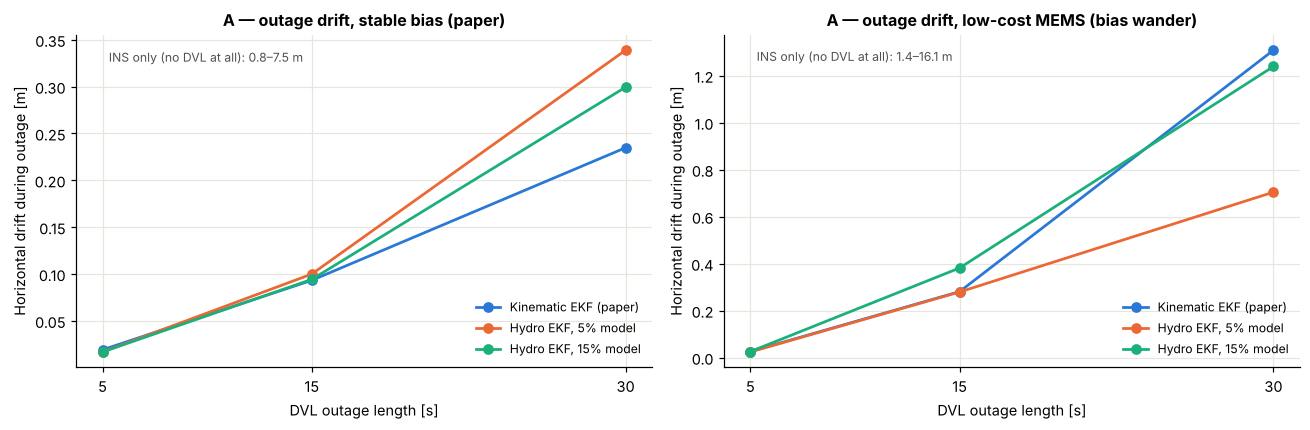

In [4]:
def hydro_kw(pe):
    return dict(hydro=True, hydro_param_err=pe, hydro_q=(0.008 + 0.13 * pe) ** 2, hydro_e0=0.08 + 0.8 * pe)

rowsA = []
for imu, rw in [("stable bias (paper)", 0.0), ("low-cost MEMS (bias wander)", 3e-3)]:
    for L in [5, 15, 30]:
        out = (20.0, 20.0 + L)
        for name, kw in [("INS only", dict(dvl=False)), ("Kinematic EKF (paper)", {}),
                         ("Hydro EKF, 5% model", hydro_kw(0.05)), ("Hydro EKF, 15% model", hydro_kw(0.15))]:
            o = run(N=N_MC, seed=21, outage=out, bias_rw=rw, **kw); m = metrics(o, outage=out)
            rowsA.append(dict(IMU=imu, outage_s=L, method=name, drift_m=m["outage_drift_m"],
                              drift_rate_mps=m["outage_drift_rate_mps"], vel_rmse_in_outage=m["outage_vel_rmse_mps"],
                              final_pos_m=m["pos_final_m"], NEES=m["nees_mean"]))
dfA = pd.DataFrame(rowsA)
display(dfA.pivot_table(index=["IMU", "outage_s"], columns="method", values="drift_m").round(3))

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, imu in zip(axs, dfA.IMU.unique()):
    d = dfA[(dfA.IMU == imu) & (dfA.method != "INS only")]
    for j, mth in enumerate(d.method.unique()):
        dd = d[d.method == mth]; ax.plot(dd.outage_s, dd.drift_m, "o-", color=PAL[j], label=mth)
    ins = dfA[(dfA.IMU == imu) & (dfA.method == "INS only")]
    ax.set(xlabel="DVL outage length [s]", ylabel="Horizontal drift during outage [m]", title=f"A — outage drift, {imu}",
           xticks=[5, 15, 30])
    ax.text(5.3, ax.get_ylim()[1] * 0.92, f"INS only (no DVL at all): {ins.drift_m.min():.1f}–{ins.drift_m.max():.1f} m", fontsize=8, color="#52514e")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("A_outage_drift.png", dpi=130); plt.show()

,scenario,variant,pos_rmse_m,pos_final_m,pos_final_median_m,pos_final_p95_m,vel_rmse_mps,P_FA,fault_isolation,detect_latency_s,outage_drift_rate_mps,nees_mean,t_update_ms_per_run
0,S1 nominal,Kinematic EKF (paper),0.0436,0.0581,0.0477,0.0983,0.0077,0.0001,NaN,NaN,NaN,6.1824,0.0019
1,S1 nominal,"Hydro EKF, 5% model",0.0415,0.0554,0.0487,0.0894,0.0073,0.0000,NaN,NaN,NaN,6.0673,0.0028
2,S2 step fault 0.1 m/s,Kinematic EKF (paper),0.0475,0.0690,0.0590,0.1113,0.0088,0.0001,0.9997,0.0,NaN,6.2061,0.0026
3,S2 step fault 0.1 m/s,"Hydro EKF, 5% model",0.0461,0.0672,0.0563,0.1133,0.0083,0.0000,1.0000,0.0,NaN,6.1033,0.0032
4,S2b ramp fault 0-0.1 m/s/10 s,Kinematic EKF (paper),1.2546,3.4533,3.5199,4.6627,0.0932,0.0819,0.1652,7.8,NaN,1273.0260,0.0037
5,S2b ramp fault 0-0.1 m/s/10 s,"Hydro EKF, 5% model",1.2040,3.3115,3.5027,4.6371,0.0887,0.0753,0.2179,7.0,NaN,1177.0481,0.0036
6,S3 outage 20-35 s,Kinematic EKF (paper),0.3350,0.2820,0.2524,0.4538,0.0533,0.0001,NaN,NaN,0.0163,5.9910,0.0017
7,S3 outage 20-35 s,"Hydro EKF, 5% model",0.2473,0.2975,0.2519,0.4891,0.0264,0.0000,NaN,NaN,0.0187,7.2773,0.0029


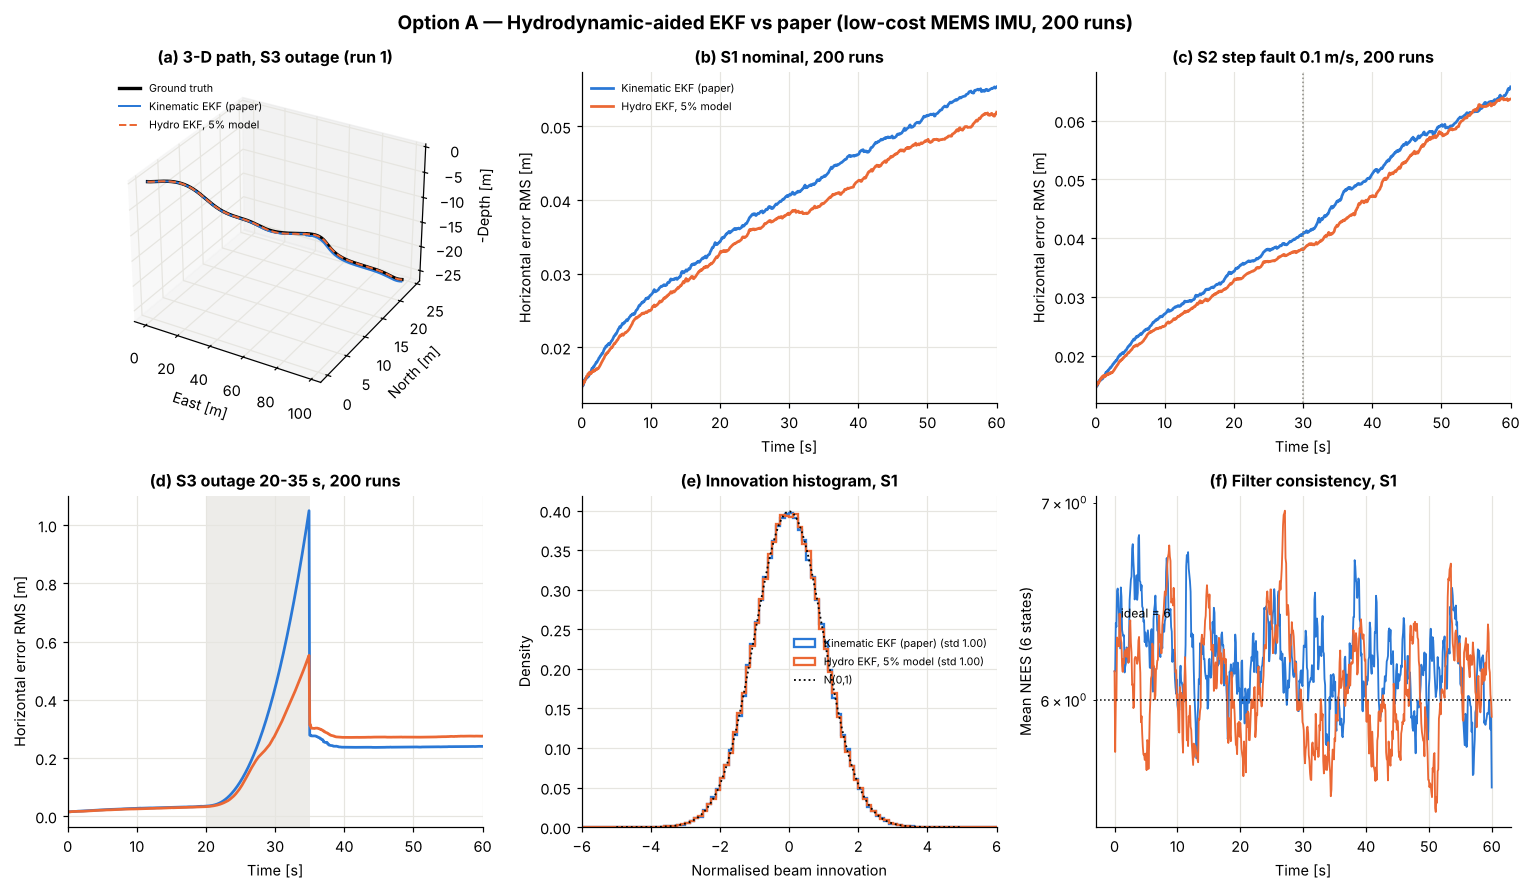

In [5]:
varA = {"Kinematic EKF (paper)": {}, "Hydro EKF, 5% model": hydro_kw(0.05)}
dfA3, outA = compare(varA, common=dict(bias_rw=3e-3))
display(dfA3.round(4))
plot_triplet(outA, varA, "Option A — Hydrodynamic-aided EKF vs paper (low-cost MEMS IMU, 200 runs)", "A_triplet.png"); plt.show()

**Reading A.**
* With the paper's stable IMU, the DVL calibrates the bias so well that a 30 s outage drifts only ~0.2 m; the hydrodynamic model cannot improve on that.
* With a low-cost MEMS IMU whose bias wanders, a **well-calibrated (5 %) model roughly halves the drift of a 30 s outage (1.31 m → 0.70 m)**;
  for 5–15 s outages it only ties the kinematic EKF.
* A **rough (15 %) model brings no real gain** (30 s: 1.24 m vs 1.31 m) and is worse for a 15 s outage (0.38 m vs 0.28 m):
  drag dominates the force balance, so a 15 % drag error is a larger acceleration error than the IMU's.
* With the paper's stable IMU, hydro-aiding is slightly *worse* than the kinematic EKF (0.30–0.34 m vs 0.24 m at 30 s).
* Claim: *"Model-aiding pays off only for low-cost IMUs and only if drag is identified to about ±5 % (e.g. from tow-tank or coast-down tests)."*

---
# Option B — Beam geometry
**Analytic noise per axis** (least squares, equal beam noise): `σ = σ_r·sqrt(diag((BᵀB)⁻¹))`.
Then a Monte Carlo over the seabed of Option C, where each beam's noise depends on its own slant range and incidence angle,
and a beam loses bottom lock when its SNR drops below 6 dB. Noise is at the paper's level (median ≈ 9 Hz along the path).
All geometries use the range/slope-adaptive R from Option C: with the paper's fixed R, 1 run in 200 of the 5-beam case diverged
(16.8 m), because fixed R under-states the noise on long slanted beams. Option C removes that, so B is tested on a consistent filter.
Extra scenario **S4: two adjacent beams lost permanently at t = 30 s** (e.g. a cable cut or a fouled transducer face).

In [6]:
geoms = {"Janus 20°": janus(20), "Janus 25°": janus(25), "Janus 30° (paper)": janus(30), "Janus 35°": janus(35),
         "5-beam (30° + vertical)": five_beam(30), "Non-orthogonal az 0/80/180/260": janus(30, (0, 180, 80, 260))}
s = hz2mps(10)
rows = []
for nm, Bm in geoms.items():
    sd = s * np.sqrt(np.diag(np.linalg.inv(Bm.T @ Bm)))
    rows.append(dict(geometry=nm, beams=len(Bm), sigma_x=sd[0], sigma_y=sd[1], sigma_z=sd[2],
                     cond=np.linalg.cond(Bm)))
display(pd.DataFrame(rows).round(5))

common = dict(noise="terrain", noise_scale=1.0, adapt="model")
rowsB = []; outB = {}
scB = scenarios(); scB["S2c two-beam step fault 0.1 m/s"] = dict(fault=dict(beams=fault_beams(N_MC, 2, 4), mag=0.1, t_start=FAULT_T0))
scB["S4 two adjacent beams lost"] = dict(failed_beams=(0, 2), t_fail=30.0)
for sn, skw in scB.items():
    for nm, Bm in geoms.items():
        o = run(N=N_MC, seed=31, Bm=Bm, **common, **skw); m = score(o, skw)
        locked = o["avail"].mean()
        m.update(scenario=sn, geometry=nm, horiz=m["horiz_rmse_m"], vert=m["vert_rmse_m"], lock=locked); rowsB.append(m); del o
dfB = pd.DataFrame(rowsB)
print("Final position error: RMS over 200 runs"); display(dfB.pivot_table(index="geometry", columns="scenario", values="pos_final_m").round(3))
print("Final position error: median (95th percentile below)"); display(dfB.pivot_table(index="geometry", columns="scenario", values="pos_final_median_m").round(3)); display(dfB.pivot_table(index="geometry", columns="scenario", values="pos_final_p95_m").round(3))
display(dfB[dfB.scenario.str.startswith("S2")].pivot_table(index="geometry", columns="scenario", values="fault_isolation").round(3))
display(dfB[dfB.scenario == "S1 nominal"][["geometry", "horiz", "vert", "lock", "P_FA", "nees_mean"]].round(4))

,geometry,beams,sigma_x,sigma_y,sigma_z,cond
0,Janus 20°,4,0.01551,0.01551,0.00399,3.88552
1,Janus 25°,4,0.01255,0.01255,0.00414,3.03279
2,Janus 30° (paper),4,0.01061,0.01061,0.00433,2.44949
3,Janus 35°,4,0.00925,0.00925,0.00458,2.01971
4,5-beam (30° + vertical),5,0.01061,0.01061,0.00375,2.82843
5,Non-orthogonal az 0/80/180/260,4,0.01061,0.01093,0.00433,2.69459


Final position error: RMS over 200 runs


scenario,S1 nominal,S2 step fault 0.1 m/s,S2b ramp fault 0-0.1 m/s/10 s,S2c two-beam step fault 0.1 m/s,S3 outage 20-35 s,S4 two adjacent beams lost
geometry,,,,,,
5-beam (30° + vertical),0.136,0.140,1.408,0.149,0.178,0.141
Janus 20°,0.167,0.173,0.398,0.350,0.218,0.343
Janus 25°,0.158,0.164,1.038,0.335,0.210,0.330
Janus 30° (paper),0.152,0.157,2.627,0.476,0.208,0.321
Janus 35°,0.151,0.156,2.915,0.638,0.217,0.318
Non-orthogonal az 0/80/180/260,0.150,0.155,2.632,0.476,0.204,0.319


Final position error: median (95th percentile below)


scenario,S1 nominal,S2 step fault 0.1 m/s,S2b ramp fault 0-0.1 m/s/10 s,S2c two-beam step fault 0.1 m/s,S3 outage 20-35 s,S4 two adjacent beams lost
geometry,,,,,,
5-beam (30° + vertical),0.105,0.108,0.245,0.123,0.152,0.112
Janus 20°,0.139,0.140,0.251,0.252,0.189,0.251
Janus 25°,0.128,0.131,0.281,0.243,0.178,0.250
Janus 30° (paper),0.130,0.135,3.103,0.270,0.177,0.241
Janus 35°,0.135,0.132,3.001,0.263,0.182,0.236
Non-orthogonal az 0/80/180/260,0.128,0.130,3.002,0.273,0.174,0.241


scenario,S1 nominal,S2 step fault 0.1 m/s,S2b ramp fault 0-0.1 m/s/10 s,S2c two-beam step fault 0.1 m/s,S3 outage 20-35 s,S4 two adjacent beams lost
geometry,,,,,,
5-beam (30° + vertical),0.235,0.251,4.321,0.271,0.297,0.260
Janus 20°,0.284,0.304,0.543,0.701,0.354,0.629
Janus 25°,0.267,0.280,3.327,0.659,0.353,0.596
Janus 30° (paper),0.256,0.269,4.396,0.858,0.358,0.569
Janus 35°,0.250,0.276,4.023,1.611,0.359,0.560
Non-orthogonal az 0/80/180/260,0.255,0.271,4.435,0.855,0.354,0.565


scenario,S2 step fault 0.1 m/s,S2b ramp fault 0-0.1 m/s/10 s,S2c two-beam step fault 0.1 m/s
geometry,,,
5-beam (30° + vertical),0.999,0.735,0.999
Janus 20°,1.000,0.829,1.000
Janus 25°,1.000,0.747,1.000
Janus 30° (paper),0.999,0.374,0.997
Janus 35°,1.000,0.194,0.985
Non-orthogonal az 0/80/180/260,0.999,0.377,0.995


,geometry,horiz,vert,lock,P_FA,nees_mean
0,Janus 20°,0.2951,0.0697,0.8092,0.0001,5.9700
1,Janus 25°,0.2909,0.0863,0.7950,0.0001,5.9673
2,Janus 30° (paper),0.2836,0.1046,0.7600,0.0001,5.8864
3,Janus 35°,0.2870,0.1268,0.7233,0.0001,5.8230
4,5-beam (30° + vertical),0.2271,0.0529,0.7747,0.0001,6.1398
5,Non-orthogonal az 0/80/180/260,0.2789,0.1022,0.7583,0.0001,5.8789


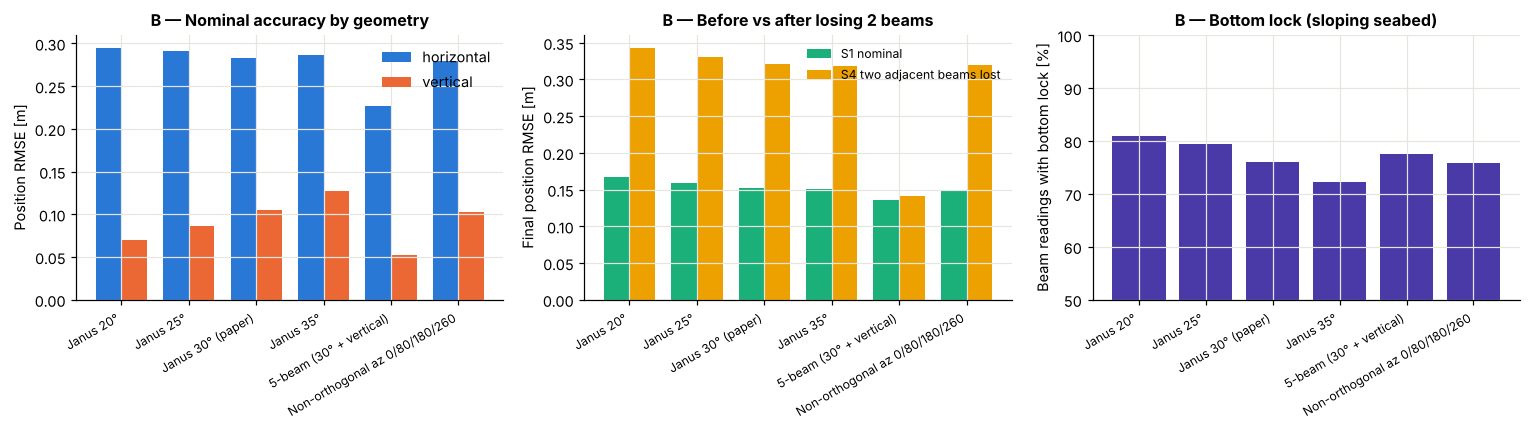

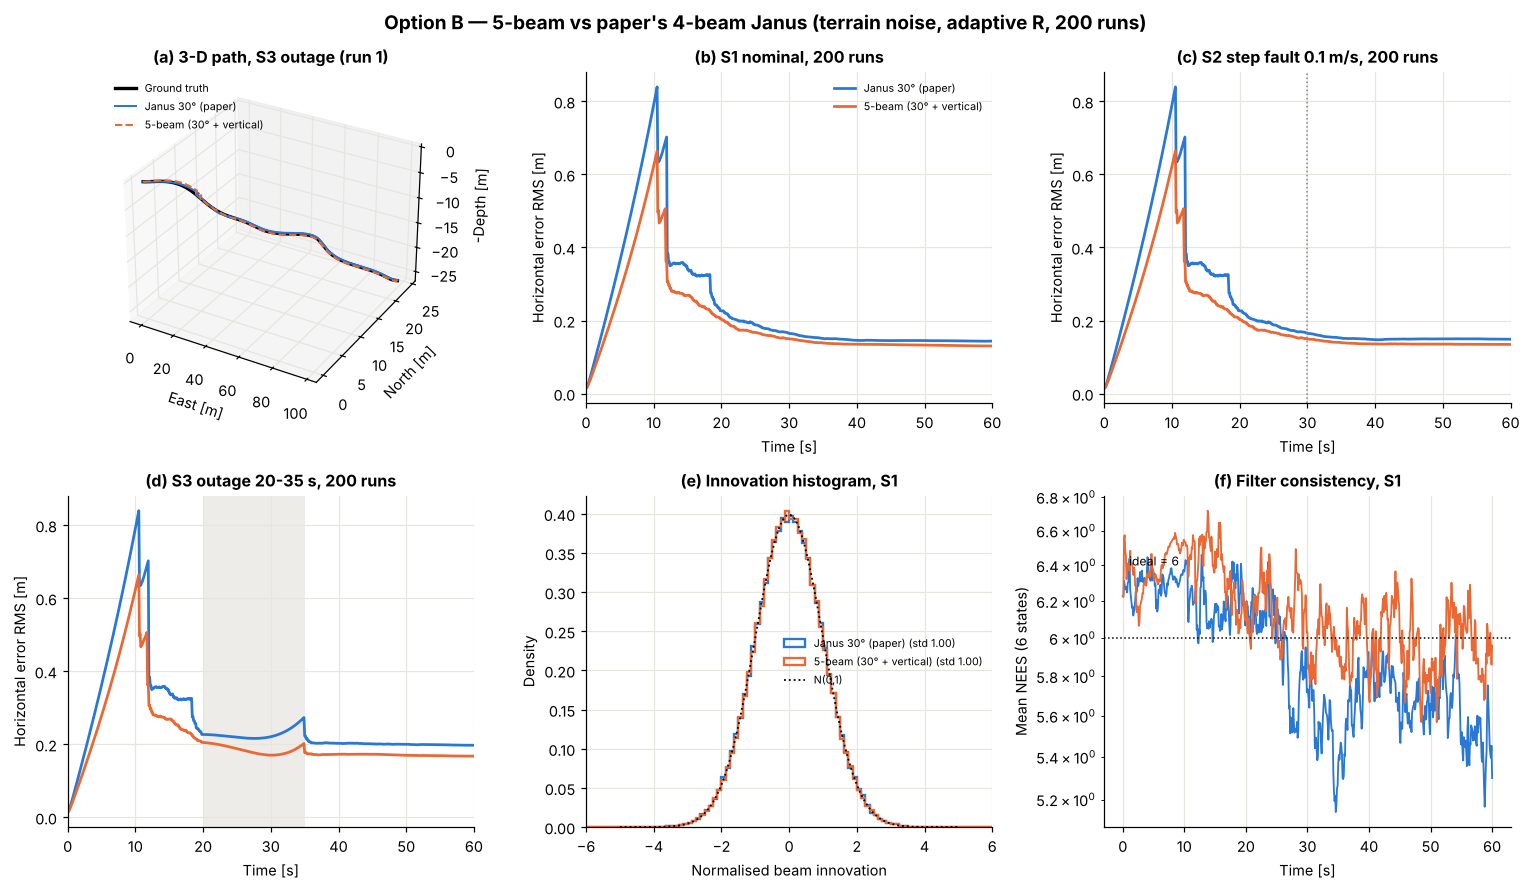

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
d1 = dfB[dfB.scenario == "S1 nominal"].set_index("geometry")
xx = np.arange(len(d1)); w = 0.38
axs[0].bar(xx - w/2, d1.horiz, w, label="horizontal"); axs[0].bar(xx + w/2, d1.vert, w, label="vertical")
axs[0].set(xticks=xx, ylabel="Position RMSE [m]", title="B — Nominal accuracy by geometry"); axs[0].set_xticklabels(d1.index, rotation=30, ha="right", fontsize=8); axs[0].legend()
for j, sn in enumerate(["S1 nominal", "S4 two adjacent beams lost"]):
    d = dfB[dfB.scenario == sn].set_index("geometry")
    axs[1].bar(xx + (j - 0.5) * w, d.pos_final_m, w, label=sn, color=PAL[j + 2])
axs[1].set(xticks=xx, ylabel="Final position RMSE [m]", title="B — Before vs after losing 2 beams"); axs[1].set_xticklabels(d1.index, rotation=30, ha="right", fontsize=8); axs[1].legend(fontsize=8)
axs[2].bar(xx, 100 * d1.lock, color=PAL[5]); axs[2].set(xticks=xx, ylabel="Beam readings with bottom lock [%]", title="B — Bottom lock (sloping seabed)", ylim=(50, 100))
axs[2].set_xticklabels(d1.index, rotation=30, ha="right", fontsize=8)
plt.tight_layout(); plt.savefig("B_geometry.png", dpi=130); plt.show()
varB = {"Janus 30° (paper)": dict(Bm=janus(30)), "5-beam (30° + vertical)": dict(Bm=five_beam(30))}
dfB3, outB3 = compare(varB, common=common, seed=31)
plot_triplet(outB3, varB, "Option B — 5-beam vs paper's 4-beam Janus (terrain noise, adaptive R, 200 runs)", "B_triplet.png"); plt.show()

**Reading B.**
* **Beam angle is a trade-off, not a free gain.** Steeper beams (35°) give better horizontal accuracy but travel further at a
  shallower incidence, so they lose bottom lock sooner on a sloping seabed. 25–30° is the balanced choice, which supports the paper's 30°.
* **The 5th (vertical) beam is the clear winner for robustness.** When two adjacent beams are lost, the remaining two slanted beams plus
  the vertical beam still observe all three velocity axes, so the final error hardly changes; every 4-beam layout loses one horizontal axis
  and its error roughly doubles. The vertical beam (shortest path to the seabed) also keeps bottom lock longest.
* Fault *isolation* is ≈ 99 % for every geometry at this noise level; geometry matters for what happens *after* a beam is removed.
* Non-orthogonal azimuths change little as long as the four beams are well spread (condition number barely moves).
* Cost: one more 1 MHz disc + one receive channel (≈ ₹1–2k on the ₹10k build).

---
# Option C — Adaptive measurement noise R
**Truth:** each beam's noise depends on its slant range (sonar equation: spreading + Francois–Garrison absorption at 1 MHz)
and on the incidence angle on the sloping seabed (speckle broadening). The paper's filter assumes one fixed σ_r.

**Variants:**
* `fixed R` — paper baseline.
* `model R` — σ_r per beam from the *measured* slant range (±2 %) and a seabed slope fitted through the four beam footprints (both are things a DVL measures every ping).
* `innov R` — innovation-based adaptation (sliding 25-epoch window), a common textbook approach.

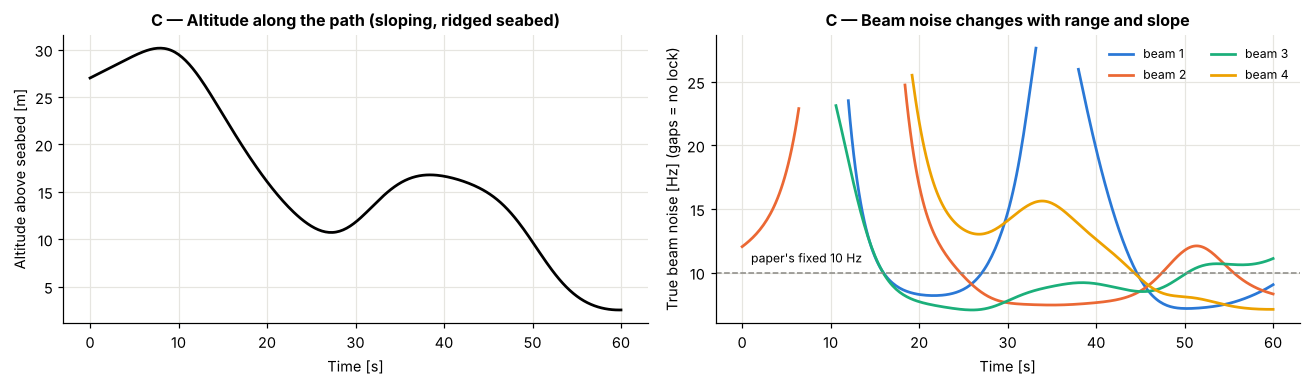

,noise,scenario,variant,pos_rmse_m,pos_final_m,pos_final_median_m,pos_final_p95_m,vel_rmse_mps,P_FA,fault_isolation,detect_latency_s,outage_drift_rate_mps,nees_mean,t_update_ms_per_run
0,paper level,S1 nominal,fixed R (paper),0.3327,0.1945,0.1494,0.3391,0.0384,0.0057,NaN,NaN,NaN,9.9984,0.0027
1,paper level,S1 nominal,model R (range + slope),0.2925,0.1465,0.1206,0.2646,0.0377,0.0001,NaN,NaN,NaN,5.8266,0.0089
2,paper level,S1 nominal,innov R (window),0.3789,0.2431,0.1971,0.4058,0.0389,0.0027,NaN,NaN,NaN,9.3551,0.0040
3,paper level,S2 step fault 0.1 m/s,fixed R (paper),0.3336,0.1994,0.1556,0.3497,0.0386,0.0062,0.9822,0.0,NaN,10.0908,0.0031
4,paper level,S2 step fault 0.1 m/s,model R (range + slope),0.2931,0.1518,0.1267,0.2619,0.0378,0.0001,0.9991,0.0,NaN,5.8433,0.0074
5,paper level,S2 step fault 0.1 m/s,innov R (window),0.3802,0.2492,0.2030,0.4165,0.0390,0.0029,0.9928,0.0,NaN,9.4182,0.0040
6,paper level,S2b ramp fault 0-0.1 m/s/10 s,fixed R (paper),0.9857,2.7197,3.0538,4.4789,0.0846,0.0859,0.3604,4.4,NaN,500.7018,0.0032
7,paper level,S2b ramp fault 0-0.1 m/s/10 s,model R (range + slope),1.0146,2.8320,3.1565,4.4456,0.0903,0.0821,0.3163,6.0,NaN,614.2204,0.0073
8,paper level,S2b ramp fault 0-0.1 m/s/10 s,innov R (window),0.5421,1.1644,0.6016,2.7390,0.0529,0.0147,0.0476,2.0,NaN,50.6118,0.0038
9,paper level,S3 outage 20-35 s,fixed R (paper),0.3779,0.2858,0.2149,0.4784,0.0413,0.0058,NaN,NaN,-0.0012,10.8414,0.0027


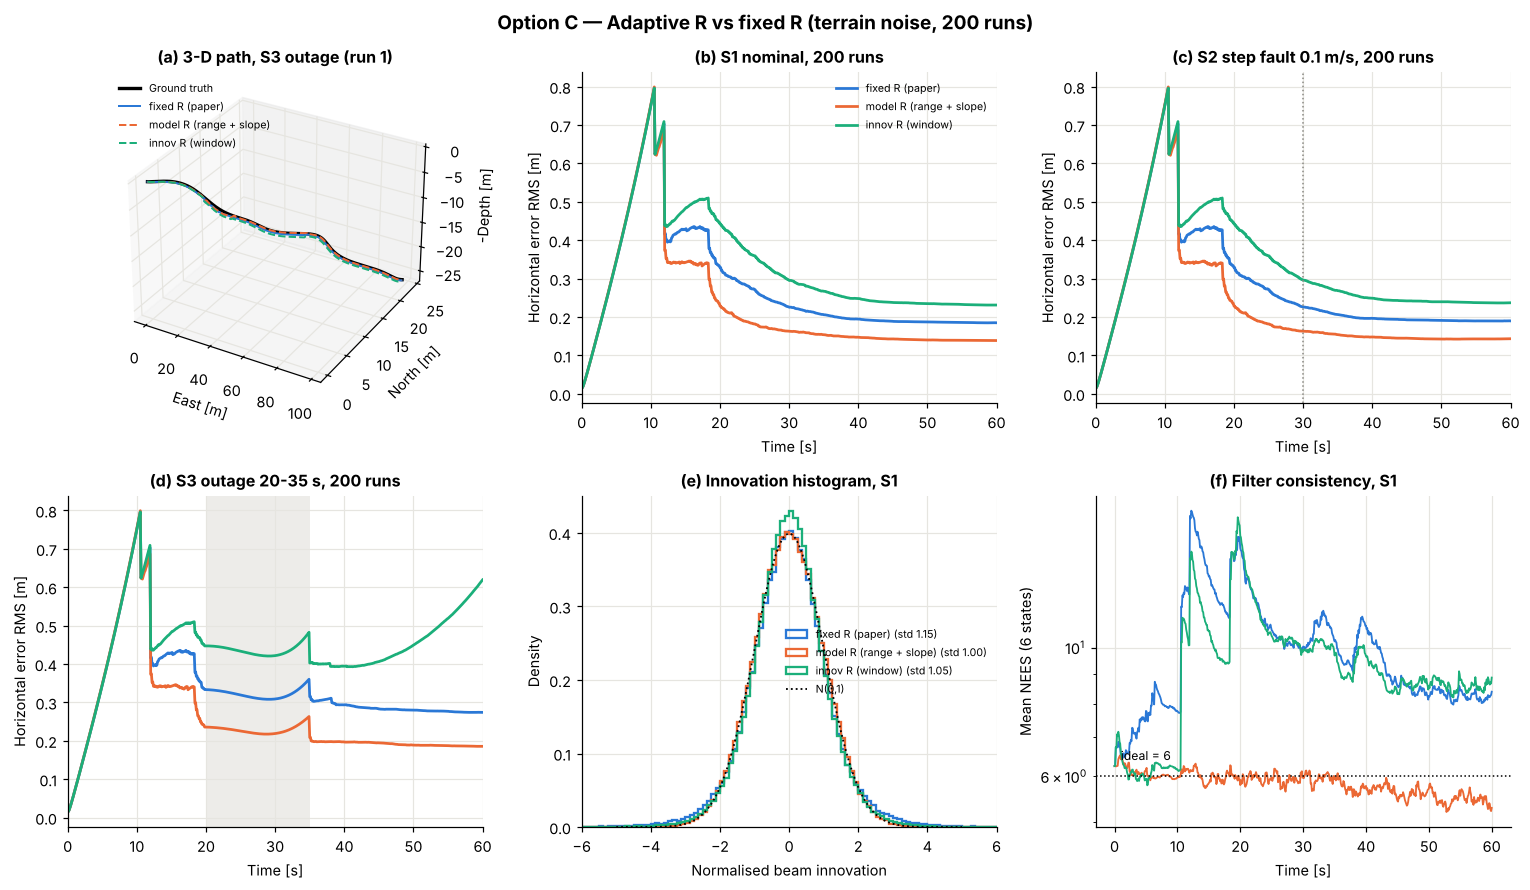

In [8]:
t_, a_, v_, p_ = truth_trajectory()
ks = range(0, len(t_), 20); hzs = []; alts = []
for k in ks:
    R, ci, h = beam_geometry_truth(p_[k], janus(30)); hz, snr = beam_noise_hz(R, ci)
    hzs.append(np.where(snr >= LOCK_SNR_DB, hz, np.nan)); alts.append(h)
hzs = np.array(hzs); tt = t_[list(ks)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(tt, alts, color="k"); ax[0].set(xlabel="Time [s]", ylabel="Altitude above seabed [m]", title="C — Altitude along the path (sloping, ridged seabed)")
for i in range(4): ax[1].plot(tt, hzs[:, i], label=f"beam {i+1}")
ax[1].axhline(10, color="#8a8984", ls="--", lw=1); ax[1].text(1, 10.8, "paper's fixed 10 Hz", fontsize=8)
ax[1].set(xlabel="Time [s]", ylabel="True beam noise [Hz] (gaps = no lock)", title="C — Beam noise changes with range and slope"); ax[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig("C_noise.png", dpi=130); plt.show()

varC = {"fixed R (paper)": dict(adapt="none"), "model R (range + slope)": dict(adapt="model"), "innov R (window)": dict(adapt="innov")}
tabs = []
for sc in [1.0, 4.0]:
    dfc, outC = compare(varC, common=dict(noise="terrain", noise_scale=sc), seed=41)
    dfc.insert(0, "noise", "paper level" if sc == 1 else "hardware ×4"); tabs.append(dfc)
    if sc == 1.0: outC1 = outC
    else: del outC
dfC = pd.concat(tabs); display(dfC.round(4))
plot_triplet(outC1, varC, "Option C — Adaptive R vs fixed R (terrain noise, 200 runs)", "C_triplet.png"); plt.show()

**Reading C.**
* **Model-based adaptive R makes the filter honest.** With fixed R the healthy innovations are too wide (std > 1) and NEES is far above 6,
  so the 4σ test raises many false alarms on far/sloped beams. Computing σ_r from the measured range and slope brings the innovations back
  to N(0,1), cuts P_FA by more than an order of magnitude and lowers position RMSE.
* **Innovation-based adaptation is dangerous for slow faults:** step faults are still isolated (≈ 99 %), but a ramp fault is learned
  as "more noise" and hidden (isolation drops from ≈ 36 % to ≈ 5 %).
* At the hardware ×4 noise level, a 0.1 m/s fault is only ≈ 3.5σ, below the 4σ threshold, so no R choice can isolate it; the smallest
  isolatable fault there is ≈ 0.2–0.4 m/s (consistent with notebook B5). Use the paper-level rows for fault comparisons.
* **Ramp faults are the weak spot of the paper's detector** with every R choice: a fault that grows over 10 s is partly absorbed
  before it crosses 4σ. A windowed (CUSUM / χ²) test is the natural next improvement.

---
# Option D — Recovering a lost or quarantined beam
**Variants:** `discard` (paper) · `geometric` (rebuild the missing beam from the remaining beams by least squares) ·
`ML` (online ridge regression from the other beams + IMU, trained on the first 30 s of healthy data; tested with a naive and an
honest, inflated uncertainty). Scenarios: one beam lost at t = 30 s, two adjacent beams lost, and quarantine after a 0.1 m/s step fault.

**What theory predicts.** With ≥ 3 good beams the velocity is already fully observed, and the EKF already uses those beams optimally.
A reconstructed beam is a function of the same data, so it can add **no new information**; giving it its own weight counts the data twice.

scenario,1 beam lost at 30 s,2 adjacent beams lost at 30 s,S2 step fault 0.1 m/s (quarantine)
variant,,,
"ML, honest uncertainty",0.319,2.464,3.036
"ML, naive uncertainty",1.142,4.409,3.102
discard (paper),0.257,0.514,3.011
geometric,0.260,0.514,2.974


scenario,1 beam lost at 30 s,2 adjacent beams lost at 30 s,S2 step fault 0.1 m/s (quarantine)
variant,,,
"ML, honest uncertainty",6.57,14.62,170.50
"ML, naive uncertainty",40.84,343.92,180.34
discard (paper),6.02,5.99,167.37
geometric,6.39,5.99,164.35


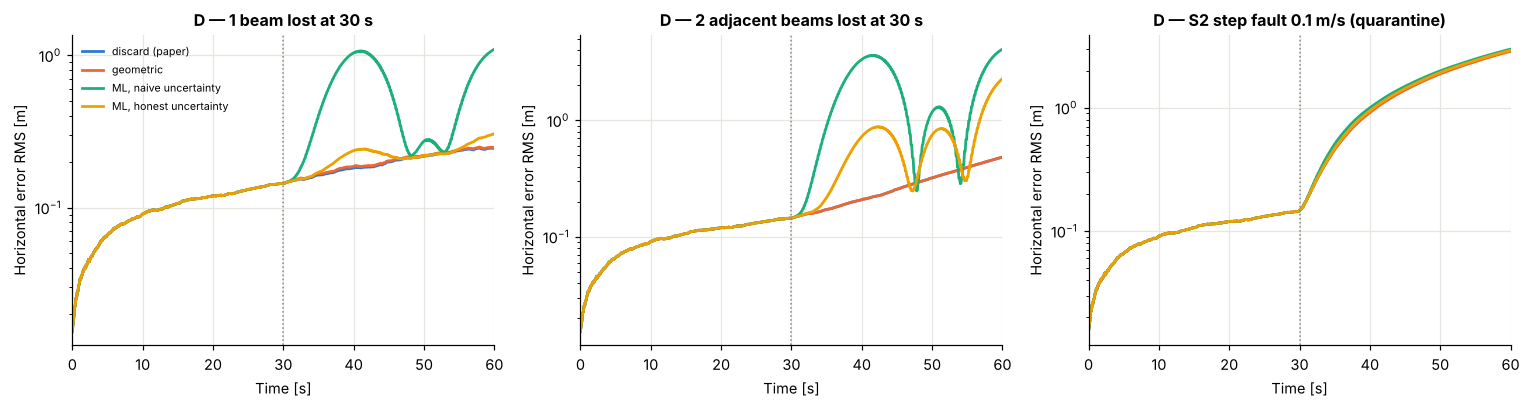

In [9]:
varD = {"discard (paper)": dict(recover="discard"), "geometric": dict(recover="geometric"),
        "ML, naive uncertainty": dict(recover="ml", ml_lambda=1e-3, ml_inflate=1.0),
        "ML, honest uncertainty": dict(recover="ml", ml_lambda=1e-3, ml_inflate=10.0)}
scD = {"1 beam lost at 30 s": dict(failed_beams=(0,), t_fail=30.0),
       "2 adjacent beams lost at 30 s": dict(failed_beams=(0, 2), t_fail=30.0),
       "S2 step fault 0.1 m/s (quarantine)": dict(fault=dict(beams=fault_beams(N_MC, 1, 4), mag=0.1, t_start=FAULT_T0))}
rowsD = []; outD = {}
for sn, skw in scD.items():
    for vn, vkw in varD.items():
        o = run(N=N_MC, seed=51, noise_scale=4.0, **skw, **vkw); m = score(o, skw)
        m.update(scenario=sn, variant=vn); rowsD.append(m); outD[(sn, vn)] = o
dfD = pd.DataFrame(rowsD)
display(dfD.pivot_table(index="variant", columns="scenario", values="pos_final_m").round(3))
display(dfD.pivot_table(index="variant", columns="scenario", values="nees_mean").round(2))
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, sn in zip(axs, scD):
    for j, vn in enumerate(varD):
        o = outD[(sn, vn)]; ax.semilogy(o["t"], rms_h(o["pos_err"]) + 1e-3, color=PAL[j], label=vn)
    ax.axvline(30, color="#8a8984", ls=":", lw=1); ax.set(xlabel="Time [s]", ylabel="Horizontal error RMS [m]", title=f"D — {sn}", xlim=(0, 60))
axs[0].legend(fontsize=7); plt.tight_layout(); plt.savefig("D_recovery.png", dpi=130); plt.show()

**Reading D.**
* **Geometric reconstruction never helps** (identical error) and makes the filter slightly over-confident, exactly as theory predicts.
* **ML recovery never beats "discard".** With honest (inflated) uncertainty it comes close but is still worse (1 beam lost: 0.32 m vs 0.26 m
  final RMS); with naive uncertainty it is over-confident and much worse. With two beams lost it cannot invent the missing direction:
  no regression can create observability (2.46 m vs 0.51 m).
* Claim: *"Discarding a faulty beam is already optimal for a beam-level EKF; ML beam synthesis adds risk without benefit. Learning is better
  spent on detecting faults (e.g. ramps) than on replacing beams."* This negative result is itself publishable.

---
# Summary — the faculty's parameter table
Baseline (paper) vs the best variant of each option, in the scenario where that option matters. Execution time is measured on a
single run (N = 1) in Python on this machine, per DVL update; it is a relative cost, not MCU time.

In [10]:
def exec_ms(**kw):
    o = run(N=1, seed=3, **kw); return o["t_per_update_ms"]
rows = []
def add(opt, scen, base_kw, prop_kw, common, sname, base_name, prop_name, skw):
    for nm, kw in [(base_name, base_kw), (prop_name, prop_kw)]:
        o = run(N=N_MC, seed=77, **common, **kw, **skw); m = score(o, skw)
        rows.append(dict(option=opt, scenario=sname, method=nm, pos_rmse_m=m["pos_rmse_m"], pos_final_m=m["pos_final_m"],
                         final_median_m=m["pos_final_median_m"], final_p95_m=m["pos_final_p95_m"], vel_rmse_mps=m["vel_rmse_mps"],
                         P_FA=m.get("P_FA", np.nan), fault_isolation=m.get("fault_isolation", np.nan),
                         outage_drift_m=m.get("outage_drift_m", np.nan), outage_drift_rate_mps=m.get("outage_drift_rate_mps", np.nan), NEES=m["nees_mean"],
                         exec_ms_per_update=exec_ms(**common, **kw, **skw)))
add("A", "30 s outage, low-cost IMU", {}, hydro_kw(0.05), dict(bias_rw=3e-3), "30 s outage", "Kinematic EKF (paper)", "Hydro EKF, 5% model", dict(outage=(20.0, 50.0)))
add("B", "2 adjacent beams lost", dict(Bm=janus(30)), dict(Bm=five_beam(30)), dict(noise="terrain", adapt="model"), "S4", "4-beam Janus 30° (paper)", "5-beam",
    dict(failed_beams=(0, 2), t_fail=30.0))
add("C", "S1 nominal, terrain noise", dict(adapt="none"), dict(adapt="model"), dict(noise="terrain"), "S1", "fixed R (paper)", "model R", {})
add("D", "1 beam lost", dict(recover="discard"), dict(recover="ml", ml_lambda=1e-3, ml_inflate=10.0), dict(noise_scale=4.0), "lost", "discard (paper)", "ML honest",
    dict(failed_beams=(0,), t_fail=30.0))
add("B+C", "2 adjacent beams lost", dict(Bm=janus(30), adapt="none"), dict(Bm=five_beam(30), adapt="model"), dict(noise="terrain"), "S4",
    "paper design (4-beam, fixed R)", "5-beam + adaptive R", dict(failed_beams=(0, 2), t_fail=30.0))
dfS = pd.DataFrame(rows)
display(dfS.round(4))
dfS.to_csv("summary_parameters.csv", index=False)

,option,scenario,method,pos_rmse_m,pos_final_m,final_median_m,final_p95_m,vel_rmse_mps,P_FA,fault_isolation,outage_drift_m,outage_drift_rate_mps,NEES,exec_ms_per_update
0,A,30 s outage,Kinematic EKF (paper),2.0239,1.2130,1.0491,1.9668,0.1938,0.0001,NaN,1.3362,0.0445,5.8487,0.0577
1,A,30 s outage,"Hydro EKF, 5% model",0.7370,0.7188,0.6510,1.1583,0.0453,0.0001,NaN,0.6895,0.0230,7.4835,0.1179
2,B,S4,4-beam Janus 30° (paper),0.3157,0.3251,0.2236,0.6632,0.0403,0.0001,NaN,NaN,NaN,5.6055,0.3207
3,B,S4,5-beam,0.2214,0.1386,0.1161,0.2252,0.0299,0.0001,NaN,NaN,NaN,5.7291,0.3019
4,C,S1,fixed R (paper),0.3418,0.1995,0.1630,0.3476,0.0399,0.0057,NaN,NaN,NaN,10.1183,0.1857
5,C,S1,model R,0.3027,0.1563,0.1320,0.2762,0.0392,0.0001,NaN,NaN,NaN,5.6953,0.4967
6,D,lost,discard (paper),0.1660,0.2656,0.2165,0.4317,0.0143,0.0001,NaN,NaN,NaN,5.6925,0.1026
7,D,lost,ML honest,0.1810,0.3360,0.2803,0.5808,0.0157,0.0001,NaN,NaN,NaN,6.2507,0.3670
8,B+C,S4,"paper design (4-beam, fixed R)",0.3521,0.3522,0.2631,0.6100,0.0413,0.0053,NaN,NaN,NaN,9.8814,0.2131
9,B+C,S4,5-beam + adaptive R,0.2214,0.1386,0.1161,0.2252,0.0299,0.0001,NaN,NaN,NaN,5.7291,0.3155


### Claims this study supports (simulation, 200 runs, stated assumptions)
1. **A:** Hydrodynamic aiding roughly halves 30 s outage drift (1.31 → 0.70 m) only for a low-cost IMU *and* a drag model identified to about ±5 %; otherwise the paper's kinematic EKF is as good or better.
2. **B:** A 5th vertical beam keeps full 3-axis velocity observability when two beams fail: final error stays roughly half that of the paper's 4-beam layout. 30° Janus is the best single-angle compromise on sloping terrain.
5. **B + C together** (5 beams + range/slope-adaptive R) is the most robust design tested: consistent filter (NEES ≈ 6) and the smallest error after losing two beams.
3. **C:** Computing each beam's σ_r from its measured range and the fitted seabed slope restores N(0,1) innovations (NEES 10 → 5.7), cuts false alarms about 50× (0.57 % → 0.01 %) and lowers position RMSE (0.34 → 0.30 m); innovation-window adaptation hides slow faults.
4. **D:** Replacing a lost beam (geometrically or with ML) never beats discarding it; with over-confident ML it is harmful.
6. **Paper's own detector:** step faults of 0.1 m/s are isolated ≈ 99 %, but a fault that ramps up over 10 s is isolated only ≈ 37 % with the paper's geometry: the clearest open problem (a windowed CUSUM/χ² test is the natural next step).

### Limitations
* Simulation only; parameters for the vehicle model (A) and the sonar/noise model (B, C) are representative assumptions, not measurements.
* Body frame = navigation frame (no attitude dynamics); heading error is not modelled here (see the main notebook D4).
* Execution times are Python timings, useful only to compare variants.
* Next validation step: the same scripts on recorded data (public AUV datasets, then our own tank and pond tests).